# Steam Publishing EDA

The goal of this project is to compare self-published games vs. traditionally published games on Steam.

I will be using a publicly available dataset which has updated listings as of October 2025. There will be a guide on how to acquire this data in the README.

Each section will have markdown text that explains my thought processes behind all my decisions.

## Section 1: Initial Set Up

Here is all the code needed to import the necessary libraries for this project. 

In [1]:
import numpy as np

import polars as pl

%matplotlib inline
import matplotlib.pyplot as plt
from sklearn import linear_model as lm

import warnings
warnings.filterwarnings("ignore")

import zipfile
import os

# Plot settings
plt.rcParams['figure.figsize'] = (12, 9)
plt.rcParams['font.size'] = 12

The next step is to read the relevant csv files for this project. Starting with applications.csv, which has the most amount of information.

In [2]:
apps = pl.read_csv(
    "steam_dataset_2025_csv/applications.csv",
    try_parse_dates=True,
    infer_schema_length=None,   # scan whole file before deciding dtypes
    null_values=["", "NA", "N/A", "null", "None", "-"],
)

As is, the apps dataframe has many unnecessary columns. It also is missing key information about developers, genres, publishers, etc.

I'll have to read the remaining files, and join based on appid. Then, I'll have to make more joins based on publisher id and so on.

In [3]:
appDev = pl.read_csv(
    "steam_dataset_2025_csv/application_developers.csv",
    try_parse_dates=True,
    infer_schema_length=None,   # scan whole file before deciding dtypes
    null_values=["", "NA", "N/A", "null", "None", "-"],
)

appGenres = pl.read_csv(
    "steam_dataset_2025_csv/application_genres.csv",
    try_parse_dates=True,
    infer_schema_length=None,   # scan whole file before deciding dtypes
    null_values=["", "NA", "N/A", "null", "None", "-"],
)

appPub = pl.read_csv(
    "steam_dataset_2025_csv/application_publishers.csv",
    try_parse_dates=True,
    infer_schema_length=None,   # scan whole file before deciding dtypes
    null_values=["", "NA", "N/A", "null", "None", "-"],
)

devs = pl.read_csv(
    "steam_dataset_2025_csv/developers.csv",
    try_parse_dates=True,
    infer_schema_length=None,   # scan whole file before deciding dtypes
    null_values=["", "NA", "N/A", "null", "None", "-"],
)

genres = pl.read_csv(
    "steam_dataset_2025_csv/genres.csv",
    try_parse_dates=True,
    infer_schema_length=None,   # scan whole file before deciding dtypes
    null_values=["", "NA", "N/A", "null", "None", "-"],
)

publishers = pl.read_csv(
    "steam_dataset_2025_csv/publishers.csv",
    try_parse_dates=True,
    infer_schema_length=None,   # scan whole file before deciding dtypes
    null_values=["", "NA", "N/A", "null", "None", "-"],
)




In [4]:
steam = apps.select(['appid', 'name', 'type', 'is_free', 'release_date', "mat_initial_price", "mat_final_price", "mat_currency", "recommendations_total", "created_at", "updated_at"])

The steam dataframe is much easier to deal with than the original apps dataframe. 

Now I need to join the other dataframes I've created into one big dataframe that I can use for proper data analysis.

In [5]:
steam = steam.join(appDev, on="appid")
steam = steam.join(appGenres, on="appid")
steam = steam.join(appPub, on="appid")

In [6]:
devs = devs.rename({"id" : "developer_id"}).rename({"name" : "developer"})
genres = genres.rename({"id" : "genre_id"}).rename({"name" : "genre"})
publishers = publishers.rename({"id" : "publisher_id"}).rename({"name" : "publisher"})

steam = steam.join(devs, on="developer_id")
steam = steam.join(genres, on="genre_id")
steam = steam.join(publishers, on="publisher_id")

## Section 2: Cleaning the Dataframe

To get a proper idea of the data I'm working with, I'll start by taking a sample of five rows from the steam data frame.

In [13]:
steam.tail(5)

appid,name,type,is_free,release_date,mat_initial_price,mat_final_price,mat_currency,recommendations_total,created_at,updated_at,developer_id,genre_id,publisher_id,developer,genre,publisher
i64,str,str,bool,date,f64,f64,str,f64,"datetime[μs, UTC]","datetime[μs, UTC]",i64,i64,i64,str,str,str
3992900,"""Hero of Sunset Demo""","""demo""",true,null,null,null,null,null,2025-09-07 12:36:43.243384 UTC,2025-09-29 06:02:12.010655 UTC,60656,113,56486,"""Starfall Games""","""Adventure""","""Flowing Dreams"""
3992900,"""Hero of Sunset Demo""","""demo""",true,null,null,null,null,null,2025-09-07 12:36:43.243384 UTC,2025-09-29 06:02:12.010655 UTC,60656,122,56486,"""Starfall Games""","""Action""","""Flowing Dreams"""
3992900,"""Hero of Sunset Demo""","""demo""",true,null,null,null,null,null,2025-09-07 12:36:43.243384 UTC,2025-09-29 06:02:12.010655 UTC,60656,144,56486,"""Starfall Games""","""RPG""","""Flowing Dreams"""
3996190,"""Project: Haste Demo""","""demo""",true,2025-09-02,null,null,null,null,2025-09-07 12:36:43.243384 UTC,2025-09-29 06:02:12.010655 UTC,88993,31,75321,"""Pronto Games Inc""","""Indie""","""Pronto Games Inc"""
3996190,"""Project: Haste Demo""","""demo""",true,2025-09-02,null,null,null,null,2025-09-07 12:36:43.243384 UTC,2025-09-29 06:02:12.010655 UTC,88993,122,75321,"""Pronto Games Inc""","""Action""","""Pronto Games Inc"""


After running the sample a few times, I noticed some features which I'd like to filter out.

What I'm interested in comparing are released games. So I plan on filtering the dataframe where "type" == "game" and "release_date" is not null.

This way, I get rid of any DLCs and demos, as well as unreleased video games.

In [16]:
steam = steam.filter(pl.col("type") == "game")
steam = steam.filter(pl.col("release_date").is_not_null())

Now I will add a new column of booleans that indicate whether or not a game is self-published.

To do this, I will compare the strings of the developer and publisher columns. As seen in the first five rows of the dataframe, the developer_id and publisher_id columns for Valve do not match each other, even though they are the same. So I will be comparing the strings instead.

In [21]:
steam.head(5)

appid,name,type,is_free,release_date,mat_initial_price,mat_final_price,mat_currency,recommendations_total,created_at,updated_at,developer_id,genre_id,publisher_id,developer,genre,publisher
i64,str,str,bool,date,f64,f64,str,f64,"datetime[μs, UTC]","datetime[μs, UTC]",i64,i64,i64,str,str,str
10,"""Counter-Strike""","""game""",false,2000-11-01,999.0,999.0,"""USD""",161854.0,2025-09-07 16:27:12.218587 UTC,2025-09-29 02:01:37.107239 UTC,59202,122,50182,"""Valve""","""Action""","""Valve"""
20,"""Team Fortress Classic""","""game""",false,1999-04-01,499.0,499.0,"""USD""",6633.0,2025-09-07 16:27:12.218587 UTC,2025-09-29 02:01:37.107239 UTC,59202,122,50182,"""Valve""","""Action""","""Valve"""
30,"""Day of Defeat""","""game""",false,2003-05-01,499.0,499.0,"""USD""",4308.0,2025-09-07 16:27:12.218587 UTC,2025-09-29 02:01:37.107239 UTC,59202,122,50182,"""Valve""","""Action""","""Valve"""
40,"""Deathmatch Classic""","""game""",false,2001-06-01,499.0,499.0,"""USD""",2338.0,2025-09-07 16:27:12.218587 UTC,2025-09-29 02:01:37.107239 UTC,59202,122,50182,"""Valve""","""Action""","""Valve"""
50,"""Half-Life: Opposing Force""","""game""",false,1999-11-01,499.0,499.0,"""USD""",22793.0,2025-09-07 16:27:12.218587 UTC,2025-09-29 02:01:37.107239 UTC,21806,122,50182,"""Gearbox Software""","""Action""","""Valve"""


In [ ]:
steam = steam.with_columns(
    (pl.col("developer") == pl.col("publisher")).alias("self-published")
)

We can verify that the new column was created correctly by looking at the first five rows again.

In [25]:
steam.head(5)

appid,name,type,is_free,release_date,mat_initial_price,mat_final_price,mat_currency,recommendations_total,created_at,updated_at,developer_id,genre_id,publisher_id,developer,genre,publisher,self-published
i64,str,str,bool,date,f64,f64,str,f64,"datetime[μs, UTC]","datetime[μs, UTC]",i64,i64,i64,str,str,str,bool
10,"""Counter-Strike""","""game""",false,2000-11-01,999.0,999.0,"""USD""",161854.0,2025-09-07 16:27:12.218587 UTC,2025-09-29 02:01:37.107239 UTC,59202,122,50182,"""Valve""","""Action""","""Valve""",true
20,"""Team Fortress Classic""","""game""",false,1999-04-01,499.0,499.0,"""USD""",6633.0,2025-09-07 16:27:12.218587 UTC,2025-09-29 02:01:37.107239 UTC,59202,122,50182,"""Valve""","""Action""","""Valve""",true
30,"""Day of Defeat""","""game""",false,2003-05-01,499.0,499.0,"""USD""",4308.0,2025-09-07 16:27:12.218587 UTC,2025-09-29 02:01:37.107239 UTC,59202,122,50182,"""Valve""","""Action""","""Valve""",true
40,"""Deathmatch Classic""","""game""",false,2001-06-01,499.0,499.0,"""USD""",2338.0,2025-09-07 16:27:12.218587 UTC,2025-09-29 02:01:37.107239 UTC,59202,122,50182,"""Valve""","""Action""","""Valve""",true
50,"""Half-Life: Opposing Force""","""game""",false,1999-11-01,499.0,499.0,"""USD""",22793.0,2025-09-07 16:27:12.218587 UTC,2025-09-29 02:01:37.107239 UTC,21806,122,50182,"""Gearbox Software""","""Action""","""Valve""",false


Now the first thing I want to know is how many self-published games there are compared to traditionally published games. To do this I will make a bar plot.

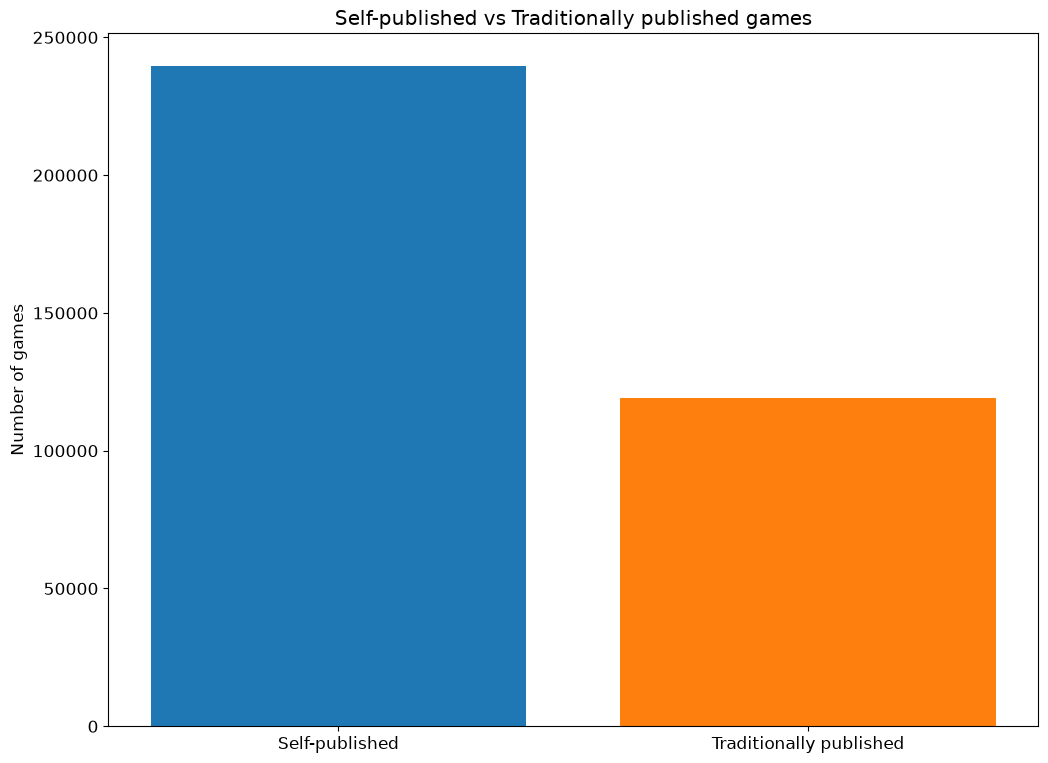

In [27]:
plot_df = (
    steam
    .select(
        pl.when(pl.col("self-published"))
          .then(pl.lit("Self-published"))
          .otherwise(pl.lit("Traditionally published"))
          .alias("category")
    )
    .group_by("category")
    .len()
)

fig, ax = plt.subplots()
ax.bar(plot_df["category"], plot_df["len"], color=["tab:blue", "tab:orange"])
ax.set_ylabel("Number of games")
ax.set_title("Self-published vs Traditionally published games")
plt.show()

This is not what I was expecting. I want to make a line plot to see how the amount of games within each publishing style has changed over time.

Is there a point where there have been more self-published games being made each year?

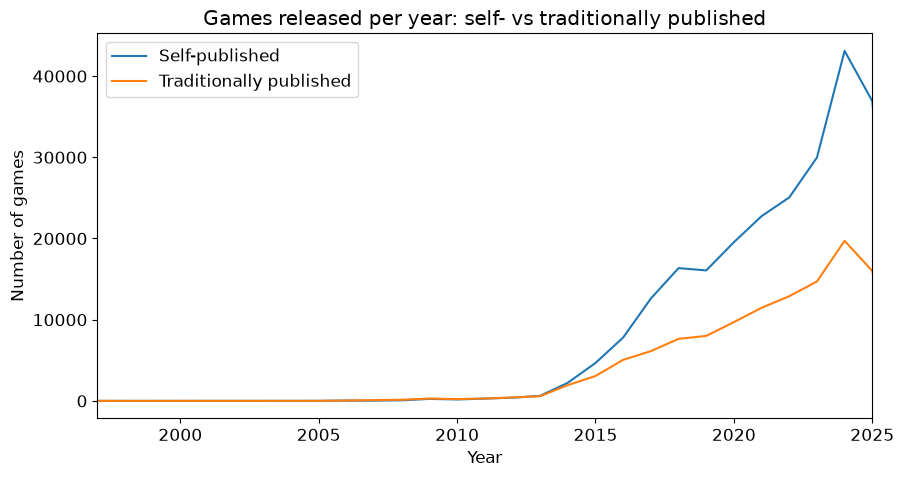

In [ ]:
plot_df = (
    steam
    .with_columns(
        pl.col("release_date").dt.year().alias("year")
    )
    .group_by("year", "self-published")
    .len()
    .sort("year")
)

fig, ax = plt.subplots(figsize=(10, 5))

for is_self, label in [(True, "Self-published"), (False, "Traditionally published")]:
    sub = plot_df.filter(pl.col("self-published") == is_self).sort("year")
    ax.plot(sub["year"], sub["len"], label=label)

ax.set_xlabel("Year")
ax.set_ylabel("Number of games")
ax.set_title("Games released per year: self- vs traditionally published")

# Every 5 years, ending on 2025
ax.set_xticks(range(1995, 2026, 5))
ax.set_xlim(1997, 2025)

ax.legend()
plt.show()

There is a big discrepancy between the two types of publishing starting around 2013.

My guess is that this has to due with the rise of indie games. As of right now, self-published games can include indie games as well as big AAA games made in studio.

The dataset I have conveniently lists "indie" as a genre.

I will test out to see the genre of a game now.

In [36]:
steam.filter(pl.col("name") == "Hades")

appid,name,type,is_free,release_date,mat_initial_price,mat_final_price,mat_currency,recommendations_total,created_at,updated_at,developer_id,genre_id,publisher_id,developer,genre,publisher,self-published
i64,str,str,bool,date,f64,f64,str,f64,"datetime[μs, UTC]","datetime[μs, UTC]",i64,i64,i64,str,str,str,bool
1145360,"""Hades""","""game""",false,2020-09-17,2499.0,2499.0,"""USD""",262410.0,2025-09-07 12:36:43.243384 UTC,2025-09-29 06:05:04.711127 UTC,74556,31,63155,"""Supergiant Games""","""Indie""","""Supergiant Games""",true
1145360,"""Hades""","""game""",false,2020-09-17,2499.0,2499.0,"""USD""",262410.0,2025-09-07 12:36:43.243384 UTC,2025-09-29 06:05:04.711127 UTC,74556,122,63155,"""Supergiant Games""","""Action""","""Supergiant Games""",true
1145360,"""Hades""","""game""",false,2020-09-17,2499.0,2499.0,"""USD""",262410.0,2025-09-07 12:36:43.243384 UTC,2025-09-29 06:05:04.711127 UTC,74556,144,63155,"""Supergiant Games""","""RPG""","""Supergiant Games""",true


This is interesting. It appears there are multiple copies of each game for every genre that it's in, meaning there's an inflation of rows.

Now the most pressing issue is to reduce the number of rows to be accurate to the actual amount of games. There's a chance that the spike in games shown in the line plot earlier is simply more games being a part of more genres.

I think the best solution would be to change the genre column into a list of strings per game. I'll also get rid of a few columns I haven't been using, such as developer id.

In [45]:
games = (
    steam
    .group_by("appid", maintain_order=True)
    .agg(
        pl.col("name").first(),
        pl.col("type").first(),
        pl.col("is_free").first(),
        pl.col("release_date").first(),
        pl.col("mat_initial_price").first(),
        pl.col("mat_final_price").first(),
        pl.col("mat_currency").first(),
        pl.col("recommendations_total").first(),
        pl.col("developer").first(),   
        pl.col("publisher").first(),   
        pl.col("genre").unique().alias("genres"),           # List[str]
        pl.col("self-published").first().alias("self_published"),
    )
)

In [50]:
steam.shape

(358525, 18)

In [ ]:
games.shape

(107567, 13)

Comparing the two dataframes of steam and games, games is much cleaner than steam.

However, there are still a few things I need to clean in game. Let's take a look at an example now.

In [51]:
games.filter(pl.col("name") == "Pyrotoad")

appid,name,type,is_free,release_date,mat_initial_price,mat_final_price,mat_currency,recommendations_total,developer,publisher,genres,self_published
i64,str,str,bool,date,f64,f64,str,f64,str,str,list[str],bool
3984130,"""Pyrotoad""","""game""",false,2025-11-03,null,null,null,null,"""WAV Games""","""Wav Games""","[""Action""]",false


Looking on Steam, Pyrotoad is a very small game. It has a price of $7.99, and there's only 3 reviews of it on Steam. Despite this, in this dataset it has no initial price and no recommendations total. This raises the question of how many games like this are in the dataframe, and what should be done about them.

Another issue that Pyrotoad shows is that developer and publisher could be the same, but spelled slightly differently. So because of that, the self_published column shows false, even though WAV Games and Wav Games are the same thing.

So before I attempt anymore data analysis, I will create normalized columns to check which games are really self-published. My initial data analysis is concerned with counts of games, so I will keep games with null prices and recommendations for now.

In [53]:
# Going to create a helper function to normalize the columns

def norm_expr(col : str):
    return (
        pl.col(col)
            .str.to_lowercase()
            .str.strip_chars()       # trim whitespace
    )

# Want to recreate the self_published column with normalized publishers and developers
games = games.drop("self_published")

games = games.with_columns(
    norm_expr("developer").alias("developer_norm"),
    norm_expr("publisher").alias("publisher_norm"),
)


In [54]:
games.filter(pl.col("name") == "Pyrotoad")

appid,name,type,is_free,release_date,mat_initial_price,mat_final_price,mat_currency,recommendations_total,developer,publisher,genres,developer_norm,publisher_norm
i64,str,str,bool,date,f64,f64,str,f64,str,str,list[str],str,str
3984130,"""Pyrotoad""","""game""",false,2025-11-03,null,null,null,null,"""WAV Games""","""Wav Games""","[""Action""]","""wav games""","""wav games"""


Now we have normalized columns we can compare!

In [55]:
games = games.with_columns(
    (pl.col("developer_norm") == pl.col("publisher_norm")).alias("self_published")
)

In [56]:
games.filter(pl.col("name") == "Pyrotoad")

appid,name,type,is_free,release_date,mat_initial_price,mat_final_price,mat_currency,recommendations_total,developer,publisher,genres,developer_norm,publisher_norm,self_published
i64,str,str,bool,date,f64,f64,str,f64,str,str,list[str],str,str,bool
3984130,"""Pyrotoad""","""game""",false,2025-11-03,null,null,null,null,"""WAV Games""","""Wav Games""","[""Action""]","""wav games""","""wav games""",true


Pyrotoads is now rightfully recognized as self-published!

It's time to recreate the bar plot and line plot from earlier using the games dataframe.

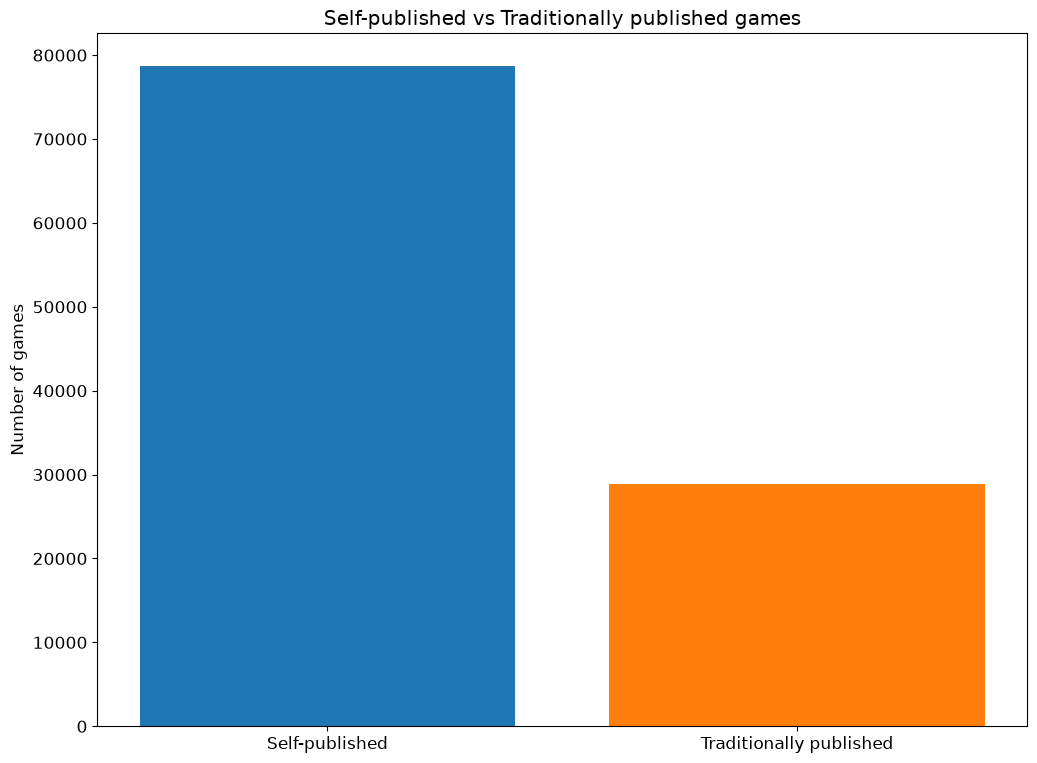

In [57]:
plot_df = (
    games
    .select(
        pl.when(pl.col("self_published"))
          .then(pl.lit("Self-published"))
          .otherwise(pl.lit("Traditionally published"))
          .alias("category")
    )
    .group_by("category")
    .len()
)

fig, ax = plt.subplots()
ax.bar(plot_df["category"], plot_df["len"], color=["tab:blue", "tab:orange"])
ax.set_ylabel("Number of games")
ax.set_title("Self-published vs Traditionally published games")
plt.show()

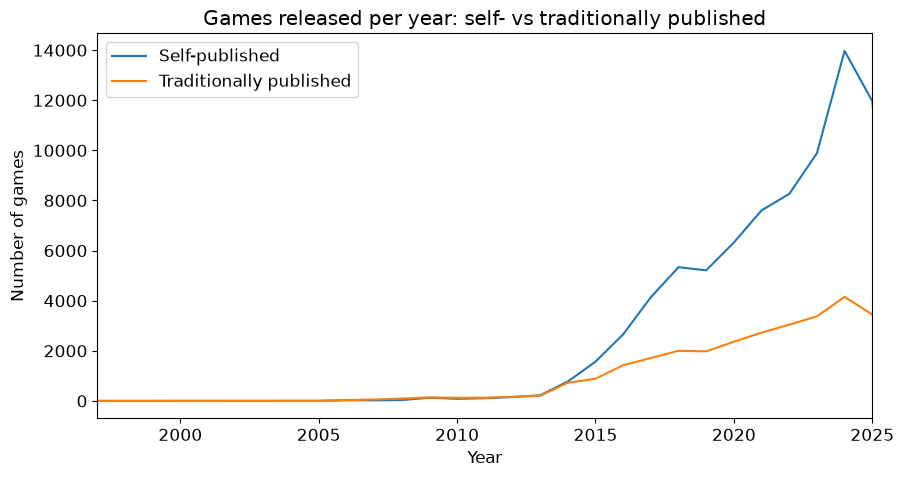

In [58]:
plot_df = (
    games
    .with_columns(
        pl.col("release_date").dt.year().alias("year")
    )
    .group_by("year", "self_published")
    .len()
    .sort("year")
)

fig, ax = plt.subplots(figsize=(10, 5))

for is_self, label in [(True, "Self-published"), (False, "Traditionally published")]:
    sub = plot_df.filter(pl.col("self_published") == is_self).sort("year")
    ax.plot(sub["year"], sub["len"], label=label)

ax.set_xlabel("Year")
ax.set_ylabel("Number of games")
ax.set_title("Games released per year: self- vs traditionally published")

# Every 5 years, ending on 2025
ax.set_xticks(range(1995, 2026, 5))
ax.set_xlim(1997, 2025)

ax.legend()
plt.show()

Interestingly, the proportion of traditionally published games compared to self-published games has decreased with the corrected data.

This makes sense, as there are many more independent developers than there are big game studios. However, this is my assumption, and I want to confirm it in two steps.

1. What is the distribution of prices between self-published and traditionally published games? 
2. How many self-published games are considered indie games? How many traditionally published games are indies?

For the first one, big game studios make more expensive games than indie studios, so I'd expect to see higher prices. 

For the second, it would be good to check what proportion of games in each publishing style are considered a part of the "indie" genre.

## Section 3: Publishing EDA

To view the distribution, I plan on creating overlaid histograms of the prices.

However, before I do that, there's one issue I need to solve.

Let's look at games that are free.

In [59]:
games.filter(pl.col("is_free") == True)

appid,name,type,is_free,release_date,mat_initial_price,mat_final_price,mat_currency,recommendations_total,developer,publisher,genres,developer_norm,publisher_norm,self_published
i64,str,str,bool,date,f64,f64,str,f64,str,str,list[str],str,str,bool
440,"""Team Fortress 2""","""game""",true,2007-10-10,null,null,null,43844.0,"""Valve""","""Valve""","[""Free To Play"", ""Action""]","""valve""","""valve""",true
570,"""Dota 2""","""game""",true,2013-07-09,null,null,null,14353.0,"""Valve""","""Valve""","[""Strategy"", ""Free To Play"", ""Action""]","""valve""","""valve""",true
630,"""Alien Swarm""","""game""",true,2010-07-19,null,null,null,299.0,"""Valve""","""Valve""","[""Free To Play"", ""Action""]","""valve""","""valve""",true
1840,"""Source Filmmaker""","""game""",true,2012-07-10,null,null,null,223.0,"""Valve""","""Valve""","[""Animation & Modeling"", ""Video Production""]","""valve""","""valve""",true
3483,"""Peggle Extreme""","""game""",true,2007-09-11,null,null,null,null,"""PopCap Games, Inc.""","""Electronic Arts""","[""Casual"", ""Free To Play""]","""popcap games, inc.""","""electronic arts""",false
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
3961580,"""Math Frenzy""","""game""",true,2025-11-01,null,null,null,null,"""Banuza""","""Banuza""","[""Indie"", ""Casual"", ""Free To Play""]","""banuza""","""banuza""",true
3961630,"""Eidolon: Fate of Fools""","""game""",true,2025-09-19,null,null,null,null,"""Antechamber""","""DigiPen Institute of Technolog…","[""Free To Play"", ""Action""]","""antechamber""","""digipen institute of technolog…",false
3964450,"""Frosten: Two Realms""","""game""",true,2025-09-10,null,null,null,null,"""KRIOGAMES""","""KRIOGAMES""","[""Indie"", ""Casual"", … ""Adventure""]","""kriogames""","""kriogames""",true


For my distribution, I intend on using the mat_initial_price column.

However, any game that is considered free has a null value for price. I still want to compare these games, so I will set their initial price to $0.

Also, as of right now, prices aren't completely accurate. For example, a game that is $24.99 is represented as 2499. I will change this too.

Finally, I will only keep games where the currency is USD or are free. Below I show the difference between the amount of games sold in USD vs other currencies.

In [62]:
games.filter(pl.col("mat_currency") != "USD").shape

(1345, 15)

In [63]:
games.filter(pl.col("mat_currency") == "USD").shape

(88305, 15)

Since there are many more games with USD currency, it should be fine to ignore the rows that aren't USD and aren't free.

In [79]:
prices = (
    games
    .filter(
        (pl.col("mat_currency") == "USD") | pl.col("is_free")
    )
    .with_columns(
        pl.when(pl.col("is_free"))
          .then(0.0)
          .otherwise(pl.col("mat_initial_price") / 100.0)
          .alias("initial_price_usd")
    )
)

prices = prices.select(["appid", "name", "is_free", "release_date", 
"initial_price_usd", "recommendations_total", "genres", "developer_norm", "publisher_norm", "self_published"])

The next step is to make an overlaid histogram comparing the initial price distribution of games with the different publishing styles.

Since there are so many games, I will be using a log scale for the y-axis.

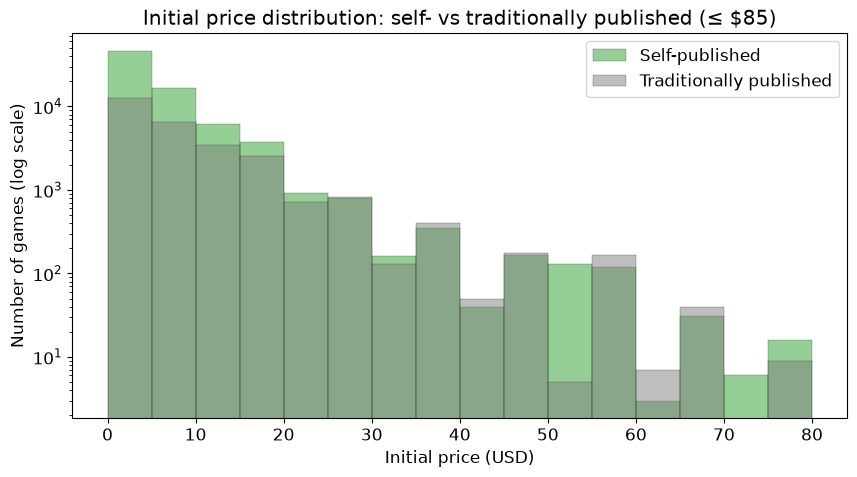

In [80]:
bins = np.arange(0, 85, 5)  # 0, 5, ..., 80
plot = prices.filter(pl.col("initial_price_usd") <= 85)

fig, ax = plt.subplots(figsize=(10, 5))
for flag, label, color in [
    (True,  "Self-published",          "tab:green"),
    (False, "Traditionally published", "tab:gray"),
]:
    sub = plot.filter(pl.col("self_published") == flag)["initial_price_usd"].drop_nulls()
    ax.hist(sub, bins=bins, alpha=0.5, label=label, color=color,
            edgecolor="black", linewidth=0.3)

ax.set_yscale("log")
ax.set_xlabel("Initial price (USD)")
ax.set_ylabel("Number of games (log scale)")
ax.set_title("Initial price distribution: self- vs traditionally published (≤ $85)")
ax.legend()
plt.show()

The vast majority of games on Steam are either free or $4.99 or less. And they are a majority self-published. This implied that the majority of games on steam are considered indie. We can test this by creating a new column which indicates whether a game is indie or not.

In [81]:
prices = prices.with_columns(
    pl.col("genres").list.contains("Indie").alias("is_indie")
)

prices.sample(5)

appid,name,is_free,release_date,initial_price_usd,recommendations_total,genres,developer_norm,publisher_norm,self_published,is_indie
i64,str,bool,date,f64,f64,list[str],str,str,bool,bool
513420,"""VR Escape The Space Station""",false,2016-08-24,1.99,null,"[""Indie"", ""Adventure"", ""RPG""]","""weyha.com""","""weyha.com""",true,true
647640,"""ShockRods""",false,2019-10-16,4.99,null,"[""Action""]","""stainless games""","""stainless games""",true,false
1617420,"""Logistics Simulator""",false,2021-08-09,0.99,null,"[""Simulation"", ""Indie"", … ""Early Access""]","""whoisthis""","""whoisthis""",true,true
898400,"""The Misadventures of Botsworth""",false,2018-08-07,1.99,null,"[""Indie""]","""team botsworth""","""team botsworth""",true,true
1216350,"""Time Hacker""",false,2025-02-25,14.99,null,"[""Simulation"", ""Indie"", … ""Action""]","""joy way""","""joy way""",true,true


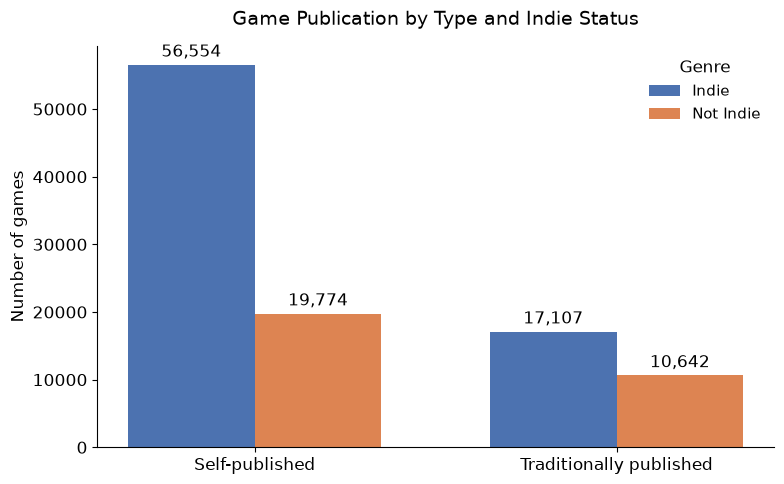

In [93]:
# Group and count the data directly from the prices dataframe
counts = (
    prices
    .group_by("self_published", "is_indie")
    .len()
)

# Etract the counts using a dictionary
# We use .get() to handle cases where a combination might be 0 (e.g., no traditional indie games)
count_dict = {
    (row["self_published"], row["is_indie"]): row["len"]
    for row in counts.iter_rows(named=True)
}

self_indie = count_dict.get((True, True), 0)
self_not   = count_dict.get((True, False), 0)
trad_indie = count_dict.get((False, True), 0)
trad_not   = count_dict.get((False, False), 0)

# Build the plot
fig, ax = plt.subplots(figsize=(8, 5))

x = np.arange(2)
width = 0.35

# Plot grouped bars
bars1 = ax.bar(x - width/2, [self_indie, trad_indie], width, label="Indie", color="#4C72B0")
bars2 = ax.bar(x + width/2, [self_not, trad_not], width, label="Not Indie", color="#DD8452")

# Formatting
ax.set_ylabel("Number of games", fontsize=12)
ax.set_title("Game Publication by Type and Indie Status", fontsize=14, pad=15)
ax.set_xticks(x, ["Self-published", "Traditionally published"], fontsize=12)
ax.legend(title="Genre", frameon=False, fontsize=11)

# Add value labels with comma formatting (e.g., 56,554)
ax.bar_label(bars1, fmt='{:,}', padding=3)
ax.bar_label(bars2, fmt='{:,}', padding=3)

# Remove top/right spines for a cleaner look
ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.show()